# 3.6 Supply-pressure index and its spatial clusters (H-c reframed)

3.6 rejected H-c as proposed: walking access to *a* centre is near-universal in HDB estates, so
distance cannot locate the weak links. The prof's framing (30 Oct) is "where is the best place to
start a new centre", which is a question about how many children share each reachable centre. This
notebook builds that **supply-pressure index** with a two-step floating catchment (2SFCA) on the OSRM
walking matrix, aggregates it to subzones, tests it for spatial clustering with global and local
Moran's I (Lecture 8) and checks how robust the high-high cluster is to the analysis choices.
Code: Minh's `scripts/pressure_index.py`, `scripts/lisa_threshold_sensitivity.py`, the pressure
figures of `scripts/make_pressure_figures.py` and the `pressure_map` / `lisa_robustness` figures of
`scripts/make_deck_figures.py`. The 2SFCA pieces live in `src/bt4015/sfca.py`, the weights in
`src/bt4015/spatial_weights.py`, the map helpers in `src/bt4015/maps.py`. Decisions:
`docs/decisions.md` 2026-11-02 (10-minute binary catchment, one unit per centre, minimum 100 children).

**Inputs**
- `large_data/walk_centres_time_min.parquet` (stage 1, OSRM): 10,769 HDB blocks x 1,796 centres, walking minutes. Read-only.
- `large_data/walk_planned_time_min.parquet`: 10,769 blocks x 13 planned centres. Read-only.
- `output/hdb_access_children.csv` (stage 1): `child_0_6` per block, subzone codes.
- `output/childcare_centres_2026.gpkg`, layers `centres` and `planned` (Jessie): service model, listed fee, subzone.
- `output/hdb_blocks.gpkg`, layers `subzones` and `subzone_stats` (stage 1).

**Outputs**
- `output/hdb_pressure_index.csv` (per block, all variants), `output/centre_catchment_pools.csv` (per centre), `output/subzone_pressure.csv` and gpkg layer `subzone_pressure` (read by 3.5 and 3.8), `output/weak_links_top15.csv` (3.8), `output/lisa_threshold_sensitivity.csv`.
- `figures/pressure_map.png`, `figures/pressure_index_lisa.png`, `figures/pressure_vs_fee.png`, `figures/lisa_robustness.png`.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "bt4015").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from bt4015.paths import DATA, OUT, FIG, LARGE

import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
from esda.moran import Moran, Moran_Local
from libpysal.weights import Queen

from bt4015.maps import (BLUE, GRID, INK, INK2, INK3, LISA, RED, base_map, choropleth, lisa_map, numbered_key,
                         pressure_bins, tidy, use_deck_style)
from bt4015.sfca import load_centres, two_sfca, wmean
from bt4015.spatial_weights import queen_with_islands_patched, rook_with_islands_patched

warnings.filterwarnings("ignore")
use_deck_style()
GPKG = OUT / "hdb_blocks.gpkg"
CENTRES_GPKG = OUT / "childcare_centres_2026.gpkg"
D0, D0_SENS = 10, 15            # catchment in walking minutes: base and sensitivity
MIN_CHILDREN = 100              # subzones with fewer children 0-6 are not tested (decision 2026-11-02)
PERMS, SEED = 9999, 4015        # LISA permutations and seed
THRESHOLDS = (0, 50, 100, 200)  # minimum-children cut-offs for the sensitivity run
LAB = {1: "HH", 2: "LH", 3: "LL", 4: "HL"}   # esda quadrant codes

## 1. Method: two-step floating catchment (2SFCA)

Let $T_{ij}$ be the walking time from HDB block $i$ to centre $j$ (OSRM foot network) and $P_i$ the
number of children aged 0-6 living in block $i$. With a binary catchment of $d_0 = 10$ minutes:

**Step 1 (per centre).** Each centre's demand pool is the children who can reach it, and its supply
ratio is one unit of supply divided by that pool (capacity is not used, per the proposal, so every
centre counts as one unit):

$$\text{pool}_j = \sum_{i:\,T_{ij} \le d_0} P_i, \qquad R_j = \frac{1}{\text{pool}_j}$$

**Step 2 (per block).** Each block's accessibility is the sum of the supply ratios of the centres it
can reach, and the **pressure** is its inverse, children per reachable centre:

$$A_i = \sum_{j:\,T_{ij} \le d_0} R_j, \qquad \text{pressure}_i = \frac{1}{A_i}$$

A block with no centre within $d_0$ has $A_i = 0$ and undefined pressure (flagged `no_centre`). The
subzone value is the children-weighted mean of $A_i$, inverted. Because $\sum_i P_i A_i$ equals the
number of centres with any HDB demand in reach, the index conserves supply: it redistributes the
centres over the children who can walk to them.

Variants in the same tables: `s15` (15-minute catchment), `fullday` (183 kindergartens excluded,
full-day supply only), `future` (plus ECDA's 13 planned centres).

## 2. Load the walk matrix, centres and demand

In [2]:
# 1. Walk matrix (blocks x centres, minutes; NaN = unreachable) and the canonical centre layer in matrix order.
T = pd.read_parquet(LARGE / "walk_centres_time_min.parquet")
centres, ids = load_centres(CENTRES_GPKG, "centres", matrix_columns=T.columns)
T = T[ids]                                           # canonical column order
kn = centres["service_model"].eq("KN").to_numpy()
print(f"{T.shape[0]:,} blocks x {T.shape[1]:,} centres; kindergartens (KN): {int(kn.sum())}; "
      f"unreachable pairs: {int(T.isna().sum().sum()):,}")

# 2. Demand: children 0-6 per block (0-4 plus the subzone share of 5-9).
blk = pd.read_csv(OUT / "hdb_access_children.csv").set_index("OBJECTID")
demand = blk["child_0_6"]
assert demand.index.equals(T.index) or set(demand.index) == set(T.index), "block ids differ from the matrix"
print(f"children 0-6 in HDB blocks: {demand.sum():,.0f}; blocks with a centre within {D0} min: "
      f"{int((T <= D0).any(axis=1).sum()):,} of {len(T):,}")

# 3. Planned centres (13) for the future variant.
TP = pd.read_parquet(LARGE / "walk_planned_time_min.parquet").reindex(T.index)
print(f"planned centres routed: {TP.shape[1]}")

10,769 blocks x 1,796 centres; kindergartens (KN): 183; unreachable pairs: 21,538
children 0-6 in HDB blocks: 176,409; blocks with a centre within 10 min: 10,736 of 10,769
planned centres routed: 13


## 3. Block-level index: base and sensitivity variants

For each variant the printed identity `sum P*A` must equal the number of centres with HDB demand in
reach: that is the conservation check of step 1 and 2.

In [3]:
specs = {"base": (T, D0), "s15": (T, D0_SENS), "fullday": (T.loc[:, ~kn], D0), "future": (pd.concat([T, TP], axis=1), D0)}
res, pools = {}, {}
for v, (Tv, d0) in specs.items():
    # 1. 2SFCA for this variant; keep A per block and the pool per centre.
    A, R, pool = two_sfca(Tv, demand, d0)
    res[v], pools[v] = A, pool
    n_served = int((pool > 0).sum())
    identity = float((demand.reindex(A.index).fillna(0) * A).sum())
    print(f"{v:8s} d0={d0:2d} min, {Tv.shape[1]:,} centres: {n_served:,} with HDB demand in reach "
          f"(sum P*A = {identity:,.1f}, should equal {n_served:,}); blocks with no centre: {int((A == 0).sum()):,}; "
          f"median supply per 1,000 children = {1000 * A.median():.2f}")
    # 2. Block columns: supply per 1,000 children, pressure (NaN where no centre), no-centre flag.
    blk[f"supply_per_1000_{v}"] = 1000 * A.reindex(blk.index)
    blk[f"pressure_{v}"] = np.where(A.reindex(blk.index) > 0, 1 / A.reindex(blk.index), np.nan)
    blk[f"no_centre_{v}"] = A.reindex(blk.index).eq(0)
keep = ["SUBZONE_C", "SUBZONE_N", "PLN_AREA_N", "child_0_6", "centres_nearest_min"] + \
       [c for c in blk.columns if c.startswith(("supply_per_1000_", "pressure_", "no_centre_"))]
blk[keep].to_csv(OUT / "hdb_pressure_index.csv")
print(f"\nblock table -> output/hdb_pressure_index.csv ({len(blk):,} rows); block pressure (base): "
      f"median {blk['pressure_base'].median():,.0f}, p90 {blk['pressure_base'].quantile(.9):,.0f} children per reachable centre")

base     d0=10 min, 1,796 centres: 1,559 with HDB demand in reach (sum P*A = 1,559.0, should equal 1,559); blocks with no centre: 33; median supply per 1,000 children = 8.23


s15      d0=15 min, 1,796 centres: 1,683 with HDB demand in reach (sum P*A = 1,683.0, should equal 1,683); blocks with no centre: 3; median supply per 1,000 children = 8.92
fullday  d0=10 min, 1,613 centres: 1,407 with HDB demand in reach (sum P*A = 1,407.0, should equal 1,407); blocks with no centre: 44; median supply per 1,000 children = 7.47


future   d0=10 min, 1,809 centres: 1,572 with HDB demand in reach (sum P*A = 1,572.0, should equal 1,572); blocks with no centre: 33; median supply per 1,000 children = 8.30



block table -> output/hdb_pressure_index.csv (10,769 rows); block pressure (base): median 121, p90 261 children per reachable centre


## 4. Per-centre catchment pools

How much HDB demand each existing centre faces within 10 minutes. Centres with an empty pool serve
private housing only (the demand pool is HDB children, the index's main limitation).

In [4]:
cpool = pd.DataFrame({"centre_id": ids, "service_model": centres["service_model"].to_numpy(),
                      "SUBZONE_C": centres["SUBZONE_C"].to_numpy(), "pool_children_0_6_10min": pools["base"].to_numpy()})
cpool.to_csv(OUT / "centre_catchment_pools.csv", index=False)
print(f"centre pools (base): median {cpool.pool_children_0_6_10min.median():,.0f} children within {D0} min, "
      f"p90 {cpool.pool_children_0_6_10min.quantile(.9):,.0f}, max {cpool.pool_children_0_6_10min.max():,.0f}, "
      f"{int((cpool.pool_children_0_6_10min == 0).sum())} centres with none")
print(cpool.groupby("service_model")["pool_children_0_6_10min"].median().round(0).to_string())

centre pools (base): median 643 children within 10 min, p90 1,892, max 3,673, 237 centres with none
service_model
CC         590.0
DS         872.0
EYC       1137.0
EYC-DS    1222.0
KN         622.0


## 5. Subzone aggregation

Children-weighted mean of $A_i$ per subzone, inverted to pressure; children with no centre in reach;
then the subzone attributes from stage 1, the median listed fee of the centres in the polygon and the
count of planned centres.

In [5]:
# 1. Weighted aggregation of every variant.
rows = []
for code_, g in blk.groupby("SUBZONE_C"):
    w_ = g["child_0_6"].to_numpy(float)
    r = {"SUBZONE_C": code_, "children_0_6": w_.sum()}
    for v in res:
        a = (g[f"supply_per_1000_{v}"] / 1000).to_numpy(float)
        m = wmean(a, w_)
        r[f"supply_per_1000_{v}"] = 1000 * m
        r[f"pressure_{v}"] = 1 / m if m and m > 0 else np.nan
        r[f"children_no_centre_{v}"] = w_[g[f"no_centre_{v}"].to_numpy(bool)].sum()
    rows.append(r)
sp = pd.DataFrame(rows)

# 2. Join to the subzone attributes (all 332 subzones; non-HDB ones stay NaN).
sz = pyogrio.read_dataframe(GPKG, layer="subzone_stats")
base_cols = ["SUBZONE_C", "SUBZONE_N", "PLN_AREA_N", "REGION_N", "area_km2", "has_hdb", "centres_n",
             "centres_fullday", "walk_nearest_min_cw", "share_children_within_10min", "pa_median_income_sgd", "geometry"]
sp = sz[base_cols].merge(sp, on="SUBZONE_C", how="left")
fee = centres[centres["fee_status"].eq("listed")].groupby("SUBZONE_C")["FULL_DAY_SC_NURSERY_FEE"].median()
sp["median_fee_listed"] = sp["SUBZONE_C"].map(fee)
planned = pyogrio.read_dataframe(CENTRES_GPKG, layer="planned", read_geometry=False)
sp["planned_centres_n"] = sp["SUBZONE_C"].map(planned.groupby("SUBZONE_C").size()).fillna(0).astype(int)
sp["pct_change_future"] = 100 * (sp["pressure_future"] / sp["pressure_base"] - 1)
hdb = sp[sp["has_hdb"] & sp["pressure_base"].notna()]
print(f"subzones: {len(sp)}; HDB subzones with a pressure value: {len(hdb)}; "
      f"median subzone pressure (base) {hdb['pressure_base'].median():,.0f}, max {hdb['pressure_base'].max():,.0f}")
print(hdb.sort_values("pressure_base", ascending=False)[["SUBZONE_N", "PLN_AREA_N", "children_0_6", "centres_n", "pressure_base",
      "pressure_s15", "pressure_fullday", "pressure_future"]].head(10).round(0).to_string(index=False))

subzones: 332; HDB subzones with a pressure value: 157; median subzone pressure (base) 101, max 596
     SUBZONE_N  PLN_AREA_N  children_0_6  centres_n  pressure_base  pressure_s15  pressure_fullday  pressure_future
TAMPINES NORTH    TAMPINES        6838.0         10          596.0         466.0             688.0            548.0
        GARDEN      TENGAH        1204.0          5          361.0         420.0             361.0            278.0
    PLANTATION      TENGAH        1960.0          4          345.0         299.0             345.0            293.0
          PARK      TENGAH        1230.0          5          318.0         268.0             318.0            318.0
        GOMBAK BUKIT BATOK         223.0          4          309.0         229.0             322.0            309.0
SEMBAWANG EAST   SEMBAWANG        2336.0          9          246.0         194.0             246.0            246.0
WOODLANDS WEST   WOODLANDS        2206.0          8          241.0         184.0        

## 6. Global and local Moran's I on log pressure

HDB subzones with at least 100 children 0-6 (140 of 157), Queen contiguity with the two islands
attached to their nearest neighbour, 9,999 permutations. Log pressure because the index is
right-skewed (Tampines North at 596 against a median near 110). HH = high pressure surrounded by
high pressure = the weak-link cluster.

In [6]:
# 1. Analysis set and weights.
h = sp[sp["has_hdb"] & (sp["children_0_6"] >= MIN_CHILDREN) & sp["pressure_base"].notna()].reset_index(drop=True)
raw_queen = Queen(list(h.geometry), silence_warnings=True)
w = queen_with_islands_patched(h)
print(f"{len(h)} HDB subzones with >= {MIN_CHILDREN} children 0-6; Queen islands patched: "
      + ", ".join(h.loc[raw_queen.islands, "SUBZONE_N"].str.title()) + f"; mean neighbours {w.mean_neighbors:.2f}")

# 2. Global and local Moran's I, seed fixed (esda's permutations use numpy's global state).
np.random.seed(SEED)
y = np.log(h["pressure_base"].to_numpy(float))
mi = Moran(y, w, permutations=PERMS)
loc = Moran_Local(y, w, permutations=PERMS, seed=SEED)
sig = loc.p_sim < 0.05
h["lisa_q"] = [LAB[q] if s_ else "ns" for q, s_ in zip(loc.q, sig)]
h["lisa_p"] = loc.p_sim
counts = h["lisa_q"].value_counts().to_dict()
print(f"global Moran's I = {mi.I:+.3f} (expected {mi.EI:+.3f}), pseudo-p = {mi.p_sim:.4f}; significant local: {counts}")

# 3. Attach the labels to the subzone table and write it (CSV + GeoPackage layer).
sp = sp.merge(h[["SUBZONE_C", "lisa_q", "lisa_p"]], on="SUBZONE_C", how="left")
sp = gpd.GeoDataFrame(sp, geometry="geometry", crs=sz.crs)
sp.drop(columns="geometry").to_csv(OUT / "subzone_pressure.csv", index=False)
sp.to_file(GPKG, layer="subzone_pressure", driver="GPKG")
print(f"subzone table -> output/subzone_pressure.csv + gpkg layer subzone_pressure ({len(sp)} rows)")

140 HDB subzones with >= 100 children 0-6; Queen islands patched: Teban Gardens, Marine Parade; mean neighbours 4.13


global Moran's I = +0.176 (expected -0.007), pseudo-p = 0.0018; significant local: {'ns': 119, 'HH': 10, 'LL': 4, 'LH': 4, 'HL': 3}
subzone table -> output/subzone_pressure.csv + gpkg layer subzone_pressure (332 rows)


## 7. Weak links

The 15 highest-pressure subzones with their LISA label and the effect of the planned centres, the
high-high set, and the rank agreement between the base index and its two sensitivity variants.

In [7]:
cols = ["SUBZONE_N", "PLN_AREA_N", "children_0_6", "centres_n", "walk_nearest_min_cw", "pressure_base",
        "supply_per_1000_base", "children_no_centre_base", "median_fee_listed", "lisa_q", "lisa_p",
        "planned_centres_n", "pressure_future", "pct_change_future"]
top = h.sort_values("pressure_base", ascending=False).head(15)
top[["SUBZONE_C"] + cols].to_csv(OUT / "weak_links_top15.csv", index=False)
print(f"Top 15 weak links (children 0-6 per reachable centre, {D0}-min walk):")
print(top[cols].round(1).to_string(index=False))
hh = h[h["lisa_q"] == "HH"].sort_values("pressure_base", ascending=False)
print(f"\nHH cluster ({len(hh)} subzones): " + ", ".join(hh["SUBZONE_N"].str.title()))
rho_s15 = h["pressure_base"].corr(h["pressure_s15"], method="spearman")
rho_fd = h["pressure_base"].corr(h["pressure_fullday"], method="spearman")
print(f"Spearman rank, pressure_base vs pressure_s15 = {rho_s15:.3f}; vs pressure_fullday = {rho_fd:.3f}")
print(f"HH subzones at the S$610 anchor fee: {int(hh['median_fee_listed'].eq(610).sum())} of {len(hh)}")

Top 15 weak links (children 0-6 per reachable centre, 10-min walk):
     SUBZONE_N  PLN_AREA_N  children_0_6  centres_n  walk_nearest_min_cw  pressure_base  supply_per_1000_base  children_no_centre_base  median_fee_listed lisa_q  lisa_p  planned_centres_n  pressure_future  pct_change_future
TAMPINES NORTH    TAMPINES        6838.4         10                  3.8          595.8                   1.7                      0.0              610.0     ns     0.4                  1            548.0               -8.0
        GARDEN      TENGAH        1203.8          5                  3.5          361.3                   2.8                      0.0              610.0     HH     0.0                  1            278.4              -23.0
    PLANTATION      TENGAH        1960.0          4                  3.4          344.5                   2.9                      0.0              610.0     HH     0.0                  1            292.7              -15.0
          PARK      TENGAH        12

## 8. Figures: pressure map, LISA map, pressure against fee

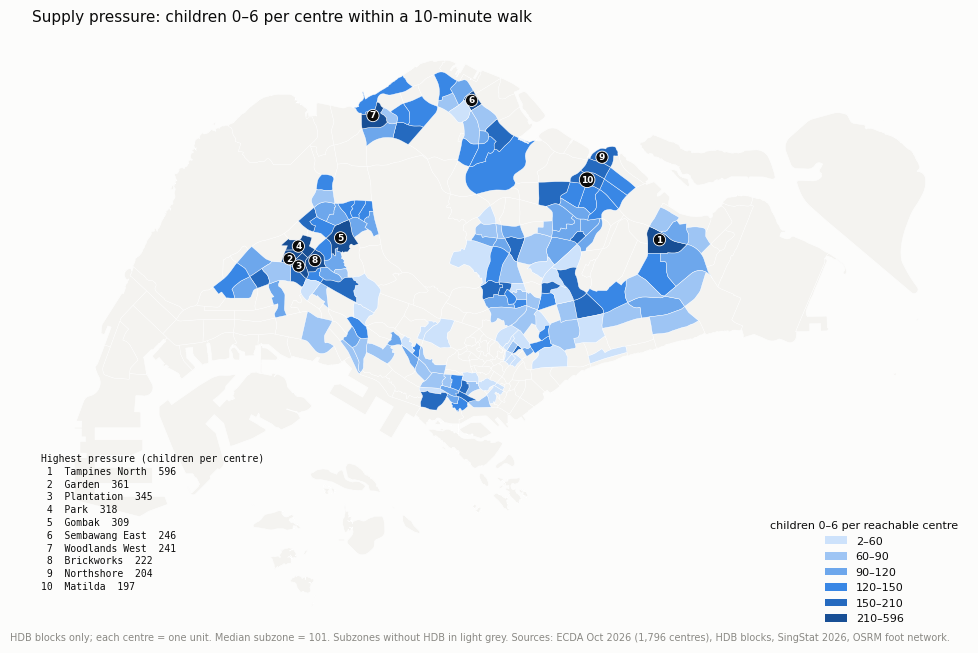

In [8]:
sz_all = pyogrio.read_dataframe(GPKG, layer="subzones")
bins = pressure_bins(hdb["pressure_base"])
fig, ax = plt.subplots(figsize=(10, 6.5))
base_map(ax, sz_all)
choropleth(ax, hdb, "pressure_base", "Supply pressure: children 0–6 per centre within a 10-minute walk", bins)
numbered_key(ax, hdb, "Highest pressure (children per centre)", col="pressure_base", n=10, extra=lambda r: f"{r['pressure_base']:,.0f}")
fig.text(0.01, 0.01, f"HDB blocks only; each centre = one unit. Median subzone = {hdb['pressure_base'].median():,.0f}. Subzones without HDB "
         "in light grey. Sources: ECDA Oct 2026 (1,796 centres), HDB blocks, SingStat 2026, OSRM foot network.", fontsize=7, color=INK3)
fig.tight_layout()
fig.savefig(FIG / "pressure_map.png", dpi=170)
plt.show()

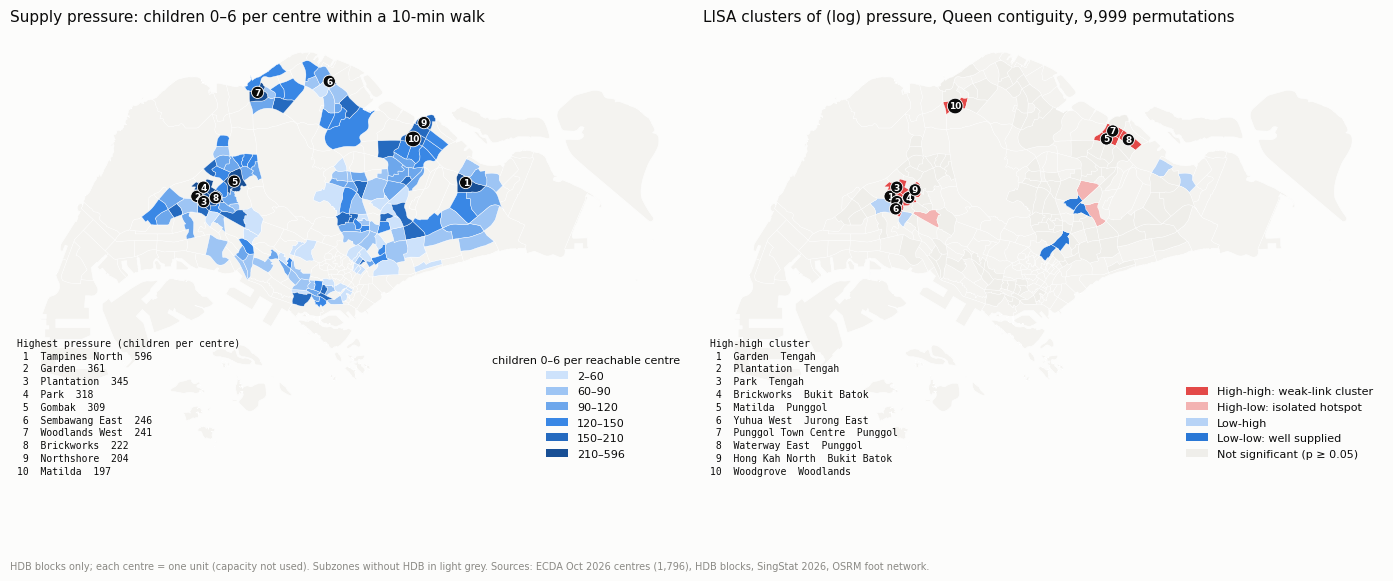

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax in axes:
    base_map(ax, sz_all)
choropleth(axes[0], hdb, "pressure_base", "Supply pressure: children 0–6 per centre within a 10-min walk", bins)
numbered_key(axes[0], hdb, "Highest pressure (children per centre)", col="pressure_base", n=10, extra=lambda r: f"{r['pressure_base']:,.0f}")
lisa_map(axes[1], h)
numbered_key(axes[1], h[h["lisa_q"].eq("HH")], "High-high cluster", col="pressure_base", extra=lambda r: f"{r['PLN_AREA_N'].title()}")
fig.text(0.01, 0.01, "HDB blocks only; each centre = one unit (capacity not used). Subzones without HDB in light grey. "
         "Sources: ECDA Oct 2026 centres (1,796), HDB blocks, SingStat 2026, OSRM foot network.", fontsize=7, color=INK3)
fig.tight_layout()
fig.savefig(FIG / "pressure_index_lisa.png", dpi=170)
plt.show()

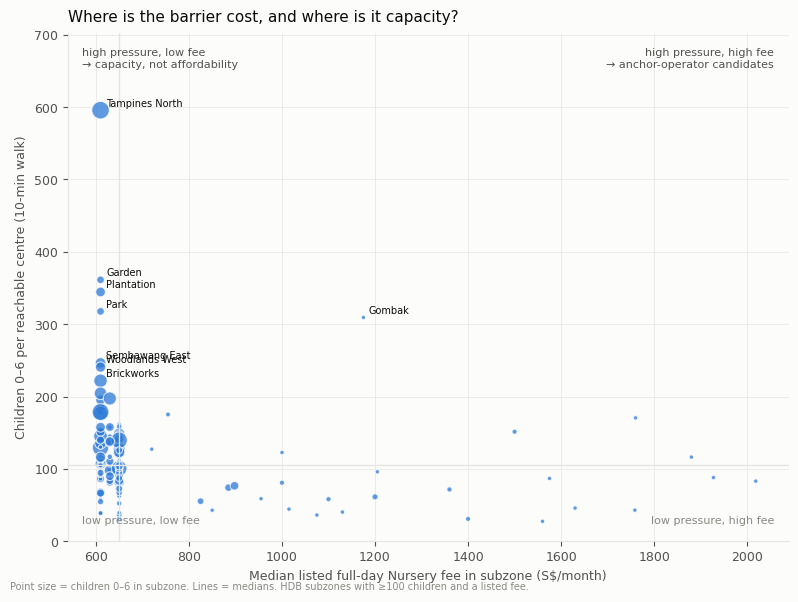

subzones plotted: 140; median fee 650, median pressure 106; high-pressure (above median) subzones at or below the median fee: 63 of 70


In [10]:
s_ = h[h["median_fee_listed"].notna()].copy()
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(s_["median_fee_listed"], s_["pressure_base"], s=np.clip(s_["children_0_6"] / 40, 10, 160), color=BLUE,
           alpha=0.75, edgecolor="white", linewidth=0.8)
xm, ym = s_["median_fee_listed"].median(), s_["pressure_base"].median()
ax.axvline(xm, color=GRID, lw=1); ax.axhline(ym, color=GRID, lw=1)
ax.set_ylim(0, s_["pressure_base"].max() * 1.18)
ax.set_xlabel("Median listed full-day Nursery fee in subzone (S$/month)")
ax.set_ylabel("Children 0–6 per reachable centre (10-min walk)")
ax.set_title("Where is the barrier cost, and where is it capacity?", loc="left", fontsize=11, pad=8)
ax.text(0.98, 0.97, "high pressure, high fee\n→ anchor-operator candidates", transform=ax.transAxes, ha="right", va="top", fontsize=8, color=INK2)
ax.text(0.02, 0.97, "high pressure, low fee\n→ capacity, not affordability", transform=ax.transAxes, ha="left", va="top", fontsize=8, color=INK2)
ax.text(0.02, 0.03, "low pressure, low fee", transform=ax.transAxes, ha="left", va="bottom", fontsize=8, color=INK3)
ax.text(0.98, 0.03, "low pressure, high fee", transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color=INK3)
for _, r in s_.sort_values("pressure_base", ascending=False).head(8).iterrows():
    ax.annotate(r["SUBZONE_N"].title(), (r["median_fee_listed"], r["pressure_base"]), fontsize=7, color=INK, xytext=(4, 3), textcoords="offset points")
tidy(ax)
fig.text(0.01, 0.01, "Point size = children 0–6 in subzone. Lines = medians. HDB subzones with ≥100 children and a listed fee.", fontsize=7, color=INK3)
fig.tight_layout()
fig.savefig(FIG / "pressure_vs_fee.png", dpi=170)
plt.show()
print(f"subzones plotted: {len(s_)}; median fee {xm:,.0f}, median pressure {ym:,.0f}; "
      f"high-pressure (above median) subzones at or below the median fee: {int(((s_['pressure_base'] > ym) & (s_['median_fee_listed'] <= xm)).sum())} "
      f"of {int((s_['pressure_base'] > ym).sum())}")

## 9. Sensitivity to the minimum-children cut-off

The 100-child floor is a judgment, so the LISA is re-run at 0, 50, 100 and 200 children. The
question is which subzones are high-high at every threshold.

In [11]:
h_all = sp[sp["has_hdb"] & sp["pressure_base"].notna()]
rows = []
for th in THRESHOLDS:
    # 1. Same weights, statistic and seed at each cut-off.
    g = h_all[h_all["children_0_6"] >= th].reset_index(drop=True)
    raw = Queen(list(g.geometry), silence_warnings=True)
    islands = ", ".join(g.loc[raw.islands, "SUBZONE_N"].str.title())
    w_th = queen_with_islands_patched(g)
    y_th = np.log(g["pressure_base"].to_numpy(float))
    np.random.seed(SEED)
    mi_th = Moran(y_th, w_th, permutations=PERMS)
    loc_th = Moran_Local(y_th, w_th, permutations=PERMS, seed=SEED)
    q = [LAB[a] if p < 0.05 else "ns" for a, p in zip(loc_th.q, loc_th.p_sim)]
    hh_th = sorted(g["SUBZONE_N"][[x == "HH" for x in q]].str.title())
    counts_th = pd.Series(q).value_counts().to_dict()
    rows.append({"min_children_0_6": th, "n_subzones": len(g), "islands_patched": islands,
                 "morans_I": round(mi_th.I, 3), "p_sim": mi_th.p_sim, "n_HH": len(hh_th), "n_LL": counts_th.get("LL", 0),
                 "n_HL": counts_th.get("HL", 0), "n_LH": counts_th.get("LH", 0), "HH_subzones": "; ".join(hh_th)})
    print(f">= {th:3d} children: n={len(g):3d} | islands: {islands or 'none'} | I={mi_th.I:+.3f} p={mi_th.p_sim:.4f} "
          f"| HH={len(hh_th)}: {', '.join(hh_th)}")
sens = pd.DataFrame(rows)
sens.to_csv(OUT / "lisa_threshold_sensitivity.csv", index=False)
core = set.intersection(*[set(r["HH_subzones"].split("; ")) for r in rows if r["min_children_0_6"] >= 50])
print(f"\nHH at every threshold from 50 to 200 ({len(core)}): {', '.join(sorted(core))}")

>=   0 children: n=157 | islands: Teban Gardens, Marine Parade | I=+0.354 p=0.0001 | HH=13: Brickworks, Garden, Guilin, Hong Kah North, Jelebu, Matilda, North Coast, Park, Plantation, Punggol Field, Punggol Town Centre, Waterway East, Yuhua West


>=  50 children: n=150 | islands: Teban Gardens, Farrer Court, Marine Parade | I=+0.205 p=0.0005 | HH=10: Brickworks, Garden, Hong Kah North, Matilda, North Coast, Park, Plantation, Punggol Town Centre, Waterway East, Yuhua West


>= 100 children: n=140 | islands: Teban Gardens, Marine Parade | I=+0.176 p=0.0018 | HH=10: Brickworks, Garden, Hong Kah North, Matilda, Park, Plantation, Punggol Town Centre, Waterway East, Woodgrove, Yuhua West


>= 200 children: n=133 | islands: Chinatown, Teban Gardens, Marine Parade | I=+0.202 p=0.0013 | HH=7: Brickworks, Garden, Hong Kah North, Park, Plantation, Punggol Town Centre, Waterway East

HH at every threshold from 50 to 200 (7): Brickworks, Garden, Hong Kah North, Park, Plantation, Punggol Town Centre, Waterway East


## 10. Rook contiguity

Queen contiguity counts corner-touching subzones as neighbours; Rook counts shared edges only. The
same LISA with Rook weights (islands patched the same way) is the weights-choice check.

In [12]:
w_rook = rook_with_islands_patched(h)
np.random.seed(SEED)
mi_rook = Moran(y, w_rook, permutations=PERMS)
loc_rook = Moran_Local(y, w_rook, permutations=PERMS, seed=SEED)
rook_q = [LAB[a] if p < 0.05 else "ns" for a, p in zip(loc_rook.q, loc_rook.p_sim)]
rook_hh = sorted(h["SUBZONE_N"][[x == "HH" for x in rook_q]].str.title())
queen_hh = sorted(hh["SUBZONE_N"].str.title())
print(f"Rook: mean neighbours {w_rook.mean_neighbors:.2f} (Queen {w.mean_neighbors:.2f}); "
      f"global Moran's I = {mi_rook.I:+.3f} (p = {mi_rook.p_sim:.4f}); HH = {len(rook_hh)}: {', '.join(rook_hh)}")
print(f"Queen HH not in Rook HH: {sorted(set(queen_hh) - set(rook_hh))}; Rook HH not in Queen HH: {sorted(set(rook_hh) - set(queen_hh))}")

Rook: mean neighbours 3.31 (Queen 4.13); global Moran's I = +0.212 (p = 0.0009); HH = 8: Brickworks, Garden, Hong Kah North, Jelebu, Park, Plantation, Punggol Town Centre, Woodgrove
Queen HH not in Rook HH: ['Matilda', 'Waterway East', 'Yuhua West']; Rook HH not in Queen HH: ['Jelebu']


## 11. Robustness grid

Which subzones are high-high under each specification (four cut-offs with Queen weights, plus Rook at
the reported cut-off).

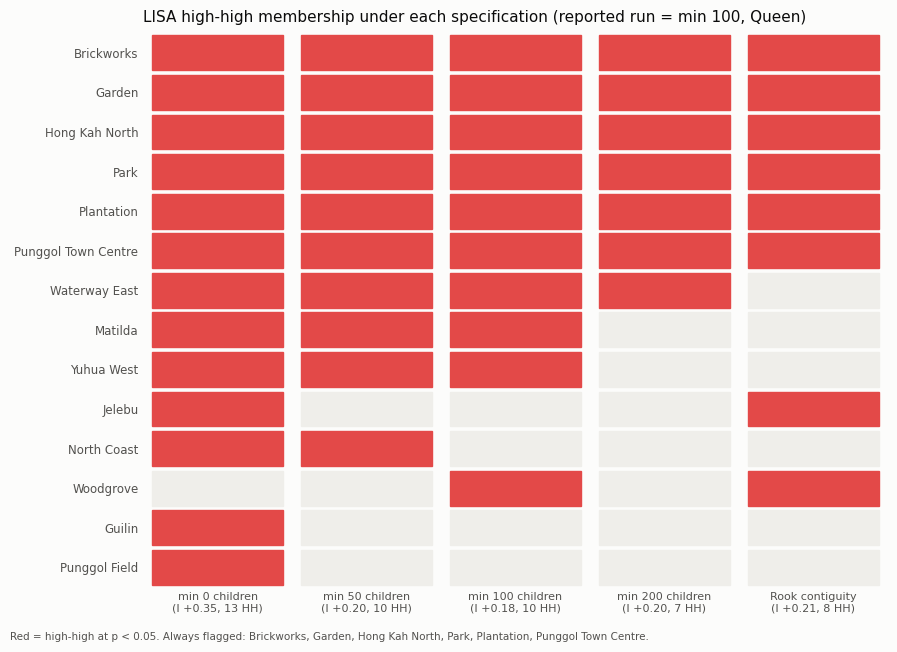

flagged under every specification: Brickworks, Garden, Hong Kah North, Park, Plantation, Punggol Town Centre


In [13]:
cols_ = {f"min {int(r.min_children_0_6)} children\n(I {r.morans_I:+.2f}, {r.n_HH} HH)": set(s.strip() for s in r.HH_subzones.split(";"))
         for r in sens.itertuples()}
cols_[f"Rook contiguity\n(I {mi_rook.I:+.2f}, {len(rook_hh)} HH)"] = set(rook_hh)
names = sorted(set().union(*cols_.values()), key=lambda n: (-sum(n in s for s in cols_.values()), n))
M = np.array([[n in s for s in cols_.values()] for n in names])
fig, ax = plt.subplots(figsize=(9, 6.5))
for r_, n in enumerate(names):
    for c_ in range(M.shape[1]):
        ax.add_patch(plt.Rectangle((c_ + 0.06, r_ + 0.06), 0.88, 0.88, color=RED if M[r_, c_] else "#efeeea"))
ax.set_xlim(0, M.shape[1]); ax.set_ylim(len(names), 0)
ax.set_xticks(np.arange(M.shape[1]) + 0.5); ax.set_xticklabels(list(cols_.keys()), fontsize=8)
ax.set_yticks(np.arange(len(names)) + 0.5); ax.set_yticklabels(names, fontsize=8.5)
ax.tick_params(length=0); ax.grid(False)
for s__ in ax.spines.values():
    s__.set_visible(False)
ax.set_title("LISA high-high membership under each specification (reported run = min 100, Queen)", loc="left", fontsize=11, pad=8)
always = [n for n in names if M[names.index(n)].sum() == M.shape[1]]
fig.text(0.01, 0.01, "Red = high-high at p < 0.05. Always flagged: " + ", ".join(always) + ".", fontsize=7.5, color=INK2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / "lisa_robustness.png", dpi=170)
plt.show()
print("flagged under every specification:", ", ".join(always))

## 12. Findings and files

Pressure clusters: global Moran's I on log pressure is positive and significant, and the high-high
cluster is the new-town belt (Tengah: Garden, Plantation, Park; Bukit Batok: Brickworks, Hong Kah
North; Jurong East: Yuhua West; Punggol: Matilda, Punggol Town Centre, Waterway East; Woodlands:
Woodgrove). Seven of them are high-high at every cut-off from 50 to 200 children; Woodgrove is
marginal (high-high only at 100), Matilda and Yuhua West drop out at 200, and Rook contiguity swaps
them for Jelebu. The highest single value is Tampines North (about 600 children per reachable
centre, not high-high because its neighbours are well supplied). Every high-pressure subzone sits
at the S$610 anchor-operator fee, so the barrier there is capacity, not affordability.

In [14]:
written = {"output/hdb_pressure_index.csv": len(blk), "output/centre_catchment_pools.csv": len(cpool),
           "output/subzone_pressure.csv (+ gpkg layer subzone_pressure)": len(sp), "output/weak_links_top15.csv": len(top),
           "output/lisa_threshold_sensitivity.csv": len(sens)}
for f, n in written.items():
    print(f"{f}: {n:,} rows")
for f in ("pressure_map.png", "pressure_index_lisa.png", "pressure_vs_fee.png", "lisa_robustness.png"):
    print(f"figures/{f}")
print(f"\nHeadline: {len(h)} subzones tested; Queen I = {mi.I:+.3f} (p = {mi.p_sim:.4f}), {len(hh)} HH; "
      f"Rook I = {mi_rook.I:+.3f}, {len(rook_hh)} HH; Spearman base vs 15-min {rho_s15:.2f}, vs full-day {rho_fd:.2f}")

output/hdb_pressure_index.csv: 10,769 rows
output/centre_catchment_pools.csv: 1,796 rows
output/subzone_pressure.csv (+ gpkg layer subzone_pressure): 332 rows
output/weak_links_top15.csv: 15 rows
output/lisa_threshold_sensitivity.csv: 4 rows
figures/pressure_map.png
figures/pressure_index_lisa.png
figures/pressure_vs_fee.png
figures/lisa_robustness.png

Headline: 140 subzones tested; Queen I = +0.176 (p = 0.0018), 10 HH; Rook I = +0.212, 8 HH; Spearman base vs 15-min 0.86, vs full-day 0.98
